# 03 · Interpretabilidade — quais variáveis mais influenciam a predição?

Três lentes complementares sobre o modelo final (LightGBM otimizado, notebook 02):

1. **Importância por ganho** — quanto cada variável reduz a perda nas árvores (visão interna do modelo);
2. **Importância por permutação** — quanto a ROC-AUC **no teste** cai quando a variável é embaralhada (visão agnóstica, mais confiável);
3. **SHAP Values** — contribuição de cada variável para **cada predição** (direção e magnitude), global e local.

Ao final, validamos o uso prático: **agregar as probabilidades por município** reproduz a taxa real de alfabetização?

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src import config, main
from src.modeling import train
from src.evaluation import interpretability as interp
from src.visualization import plots as vp

vp.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = main.step_dataset()
s = main.step_split(df)   # mesmo particionamento (semente fixa) do notebook 02
pipe, perm, sv, Xt = main.step_interpret(s, n_perm=60_000, n_shap=5000)
gain = pd.read_csv(config.REPORTS_DIR / "importancia_ganho.csv")

## 1. Importância por ganho e por permutação

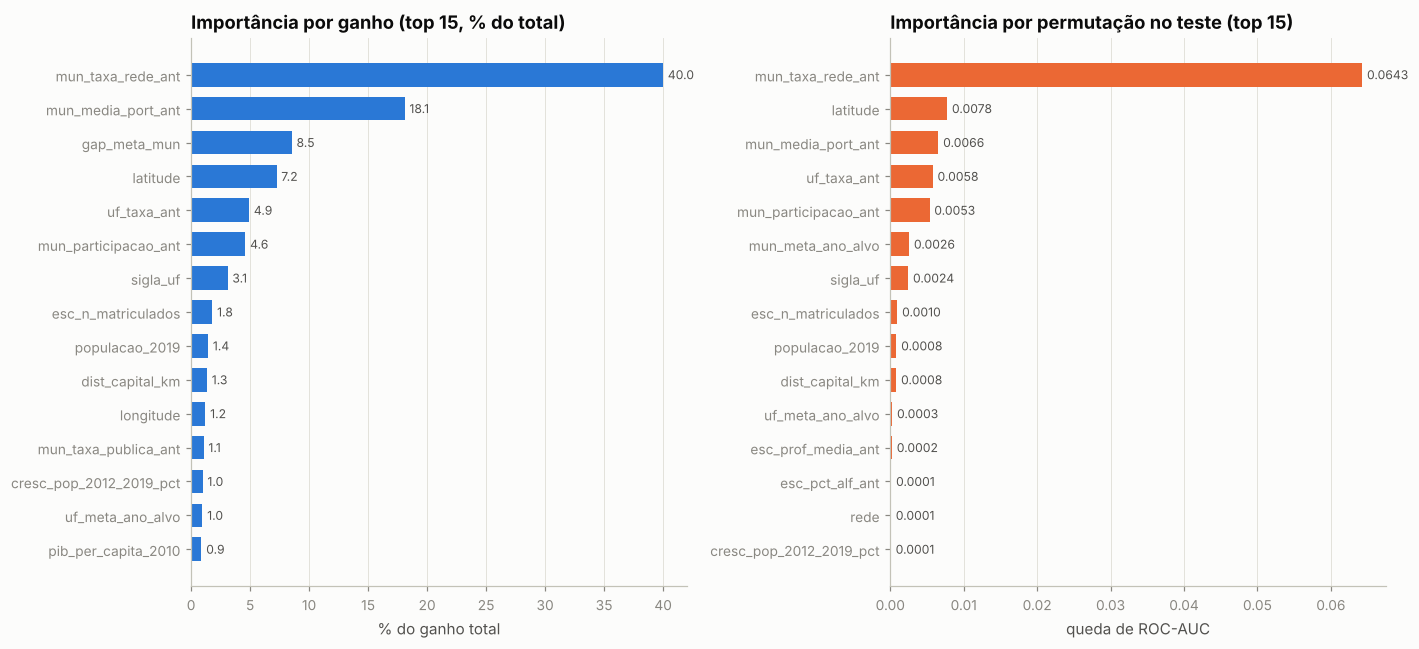

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
g = gain.head(15).set_index("feature")["importancia_pct"]
vp.barh(g, "Importância por ganho (top 15, % do total)", "% do ganho total", ax=axes[0])
p = perm.head(15).set_index("feature")["queda_auc_media"]
vp.barh(p, "Importância por permutação no teste (top 15)", "queda de ROC-AUC", color=vp.CAT[1], fmt="{:.4f}", ax=axes[1])
fig.tight_layout(); vp.save(fig, "interp_importancias"); plt.show()

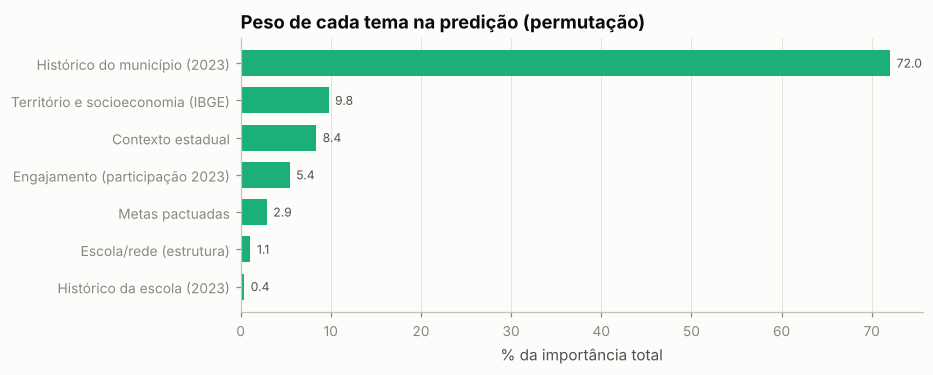

,% importância
Histórico do município (2023),72.0000
Território e socioeconomia (IBGE),9.8000
Contexto estadual,8.4000
Engajamento (participação 2023),5.4000
Metas pactuadas,2.9000
Escola/rede (estrutura),1.1000
Histórico da escola (2023),0.4000


In [3]:
# Importância agregada por tema (soma da queda de AUC por permutação)
TEMAS = {
    "Histórico do município (2023)": ["mun_taxa_rede_ant", "mun_taxa_publica_ant", "mun_media_port_ant"],
    "Engajamento (participação 2023)": ["mun_participacao_ant", "esc_taxa_presenca_ant"],
    "Histórico da escola (2023)": ["esc_pct_alf_ant", "esc_prof_media_ant", "esc_n_alunos_ant"],
    "Metas pactuadas": ["mun_meta_ano_alvo", "uf_meta_ano_alvo"],
    "Contexto estadual": ["uf_taxa_ant", "sigla_uf", "regiao"],
    "Território e socioeconomia (IBGE)": ["capital", "dist_capital_km", "populacao_2019", "cresc_pop_2012_2019_pct",
                                          "pib_per_capita_2010", "latitude", "longitude", "porte_municipio"],
    "Escola/rede (estrutura)": ["esc_n_matriculados", "rede"],
}
tema = pd.Series({t: perm.set_index("feature").reindex(cols)["queda_auc_media"].clip(lower=0).sum() for t, cols in TEMAS.items()})
tema_pct = 100 * tema / tema.sum()
ax = vp.barh(tema_pct, "Peso de cada tema na predição (permutação)", "% da importância total", color=vp.CAT[2])
vp.save(ax.figure, "interp_temas"); plt.show()
tema_pct.sort_values(ascending=False).round(1).to_frame("% importância")

## 2. SHAP — visão global

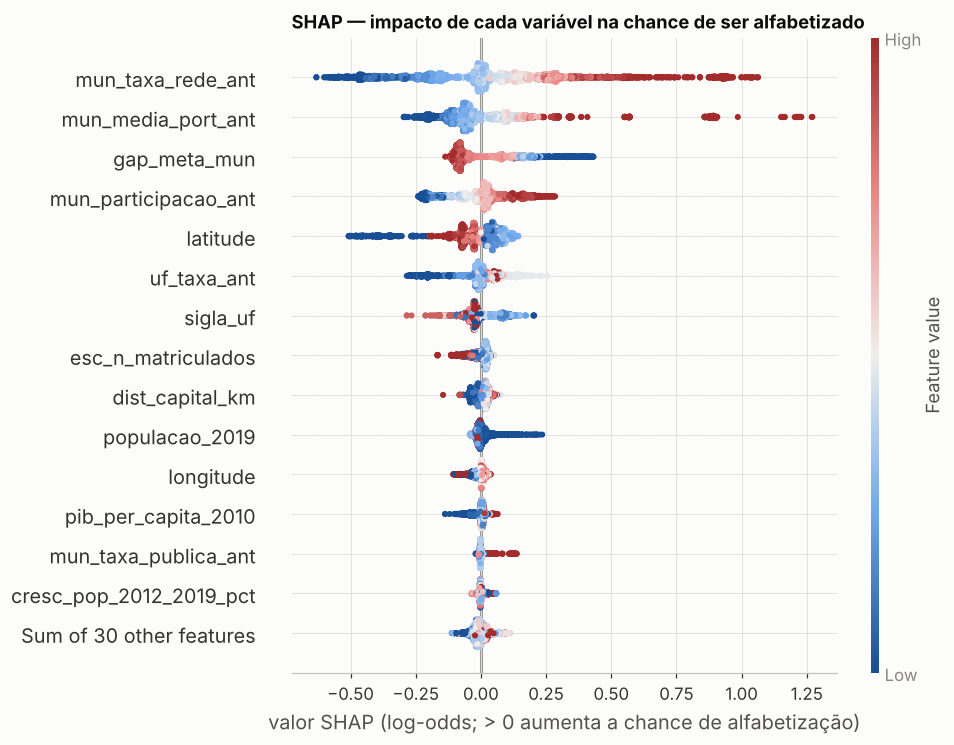

,feature,shap_medio_abs
0,mun_taxa_rede_ant,0.2096
1,mun_media_port_ant,0.1192
2,gap_meta_mun,0.1044
3,mun_participacao_ant,0.0788
4,latitude,0.0681
5,uf_taxa_ant,0.0486
6,sigla_uf,0.0429
7,esc_n_matriculados,0.0232
8,dist_capital_km,0.0200
9,populacao_2019,0.0169


In [4]:
fig = plt.figure(figsize=(9, 7))
shap.plots.beeswarm(sv, max_display=15, show=False, color=vp.DIV_CMAP)
plt.title("SHAP — impacto de cada variável na chance de ser alfabetizado", loc="left", fontweight="bold", fontsize=12)
plt.xlabel("valor SHAP (log-odds; > 0 aumenta a chance de alfabetização)")
vp.save(plt.gcf(), "interp_shap_beeswarm"); plt.show()
interp.shap_summary(sv).head(15)

**Como ler:** cada ponto é um aluno; a cor é o valor da variável (vermelho = alto, azul = baixo) e a posição horizontal é o
efeito na previsão. Ex.: municípios com **taxa 2023 alta** (vermelho) empurram a previsão para a direita (mais chance).

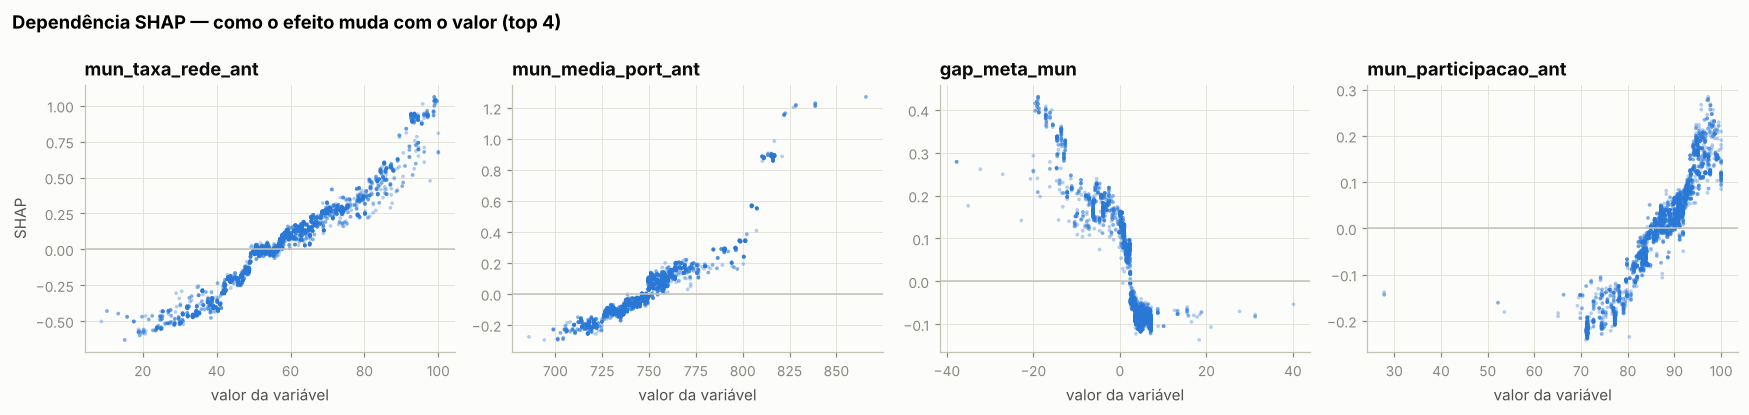

In [5]:
top = interp.shap_summary(sv)["feature"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f in zip(axes, top):
    x = Xt[f]; y = sv[:, f].values
    ax.scatter(x, y, s=6, alpha=0.35, color=vp.CAT[0], edgecolors="none")
    ax.axhline(0, color=vp.AXIS, lw=1)
    ax.set(title=f, xlabel="valor da variável", ylabel="SHAP" if f == top[0] else "")
fig.suptitle("Dependência SHAP — como o efeito muda com o valor (top 4)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); vp.save(fig, "interp_shap_dependencia"); plt.show()

## 3. SHAP — explicação local (um aluno de alto risco)

Probabilidade prevista de alfabetização: 26.8%


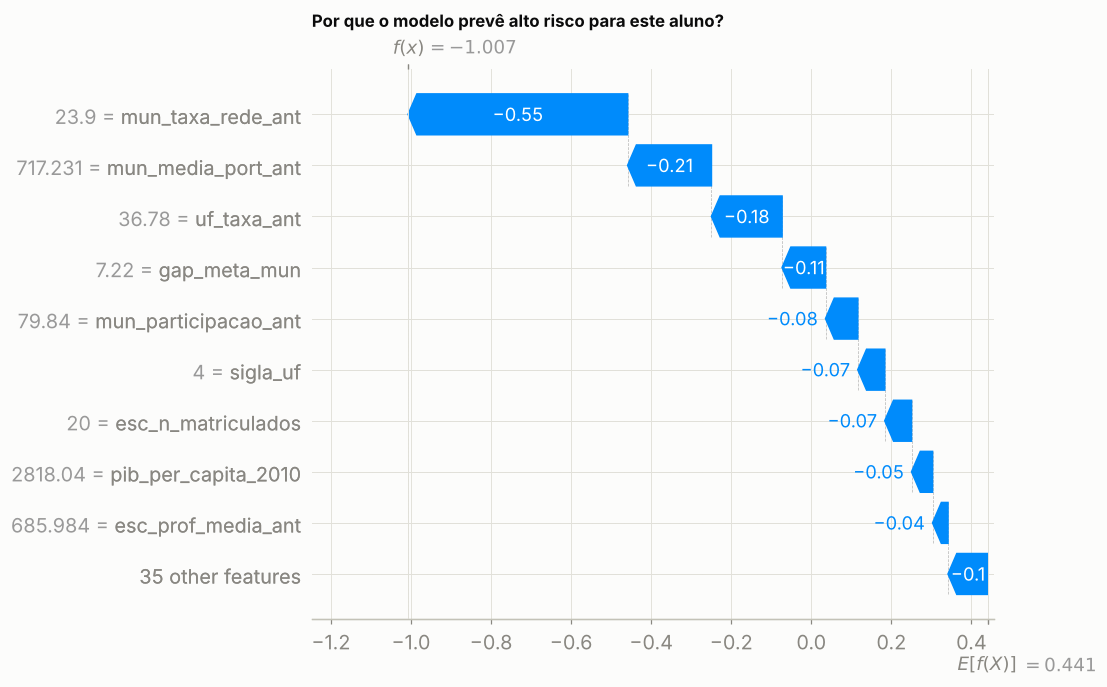

In [6]:
proba = pipe.named_steps["model"].predict_proba(Xt.values)[:, 1]
i = int(np.argmin(proba))
print(f"Probabilidade prevista de alfabetização: {proba[i]:.1%}")
fig = plt.figure()
shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.title("Por que o modelo prevê alto risco para este aluno?", loc="left", fontweight="bold", fontsize=11)
vp.save(plt.gcf(), "interp_shap_waterfall"); plt.show()

A explicação local é a base de um uso **transparente** em política pública: o gestor vê *por que* uma escola foi
priorizada (ex.: município com taxa baixa em 2023 + baixa participação), não apenas uma pontuação.

## 4. Do aluno ao território — a agregação funciona?

Municípios de teste (≥ 30 alunos): 753 · correlação = 0.813 · erro absoluto médio = 8.1 p.p. · viés = -0.0 p.p.
Baseline ingênuo (repetir a taxa de 2023), mesmos 747 municípios: correlação = 0.691 · MAE = 11.4 p.p.  →  modelo: MAE = 8.0 p.p. (29% menos erro)


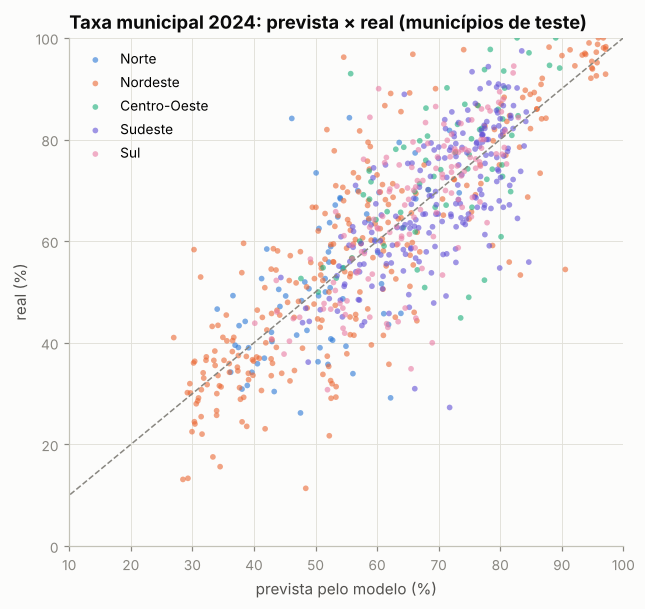

In [7]:
agg = main.step_municipal_validation(s)
m = json.loads((config.REPORTS_DIR / "metricas.json").read_text())["agregacao_municipal_teste"]
print(f"Municípios de teste (≥ 30 alunos): {m['municipios']} · correlação = {m['correlacao']:.3f} · "
      f"erro absoluto médio = {m['mae_pp']:.1f} p.p. · viés = {m['vies_pp']:+.1f} p.p.")
b = m["baseline_ano_anterior"]
print(f"Baseline ingênuo (repetir a taxa de 2023), mesmos {b['municipios']} municípios: correlação = {b['correlacao']:.3f} · "
      f"MAE = {b['mae_pp']:.1f} p.p.  →  modelo: MAE = {b['mae_modelo_mesmos_municipios_pp']:.1f} p.p. "
      f"({1 - b['mae_modelo_mesmos_municipios_pp'] / b['mae_pp']:.0%} menos erro)")
big = agg[agg.alunos >= 30]
fig, ax = plt.subplots(figsize=(6.5, 6))
for r, c in vp.REGIAO_COR.items():
    d = big[big.regiao == r]
    ax.scatter(d.taxa_prevista, d.taxa_real, s=14, alpha=0.6, color=c, label=r, edgecolors="none")
ax.plot([0, 100], [0, 100], ls="--", color=vp.MUTED, lw=1)
ax.set(xlim=(10, 100), ylim=(0, 100), title="Taxa municipal 2024: prevista × real (municípios de teste)",
       xlabel="prevista pelo modelo (%)", ylabel="real (%)")
ax.legend(loc="upper left")
vp.save(fig, "interp_agregacao_municipal"); plt.show()

## 5. Conclusões — quais variáveis possuem maior influência?

* O **histórico do próprio município** (taxa da rede e proficiência média em 2023) domina: ≈ 70% da importância por permutação e as
  duas primeiras posições no SHAP. Territórios que já alfabetizavam bem tendem a continuar — e o contrário também.
* **Contexto estadual e território** (taxa da UF, `sigla_uf`, latitude) formam o segundo bloco: capturam políticas estaduais
  (ex.: regime de colaboração do Ceará) e choques regionais (enchentes do RS em 2024).
* **Engajamento** (participação na avaliação em 2023) vem em seguida e é o fator mais **acionável**: participação alta empurra a
  previsão para cima de forma consistente (SHAP).
* **Esforço exigido pela meta** (`gap_meta_mun`): municípios com grande distância até a meta têm menor chance — reflexo do histórico, não causa.
* **Riqueza (PIB per capita) e porte** pesam pouco quando o histórico é conhecido → **gestão educacional explica mais que renda**.
* O **histórico da escola** praticamente não acrescenta (permutação ≈ 0): turmas de 2º ano são pequenas e mudam a cada ano
  (correlação escola 2023→2024 ≈ 0,26) — o sinal está no **sistema** (rede municipal), não na escola isolada.
* **Do aluno ao território:** somando as probabilidades, o modelo reproduz a taxa 2024 dos municípios de teste (correlação ≈ 0,81, viés ≈ 0)
  e erra ≈ 30% menos que a regra ingênua "repetir o resultado do ano anterior". É nesse nível que ele deve ser usado.